# Assign SNPs to genes

In [33]:
# rm(list=ls())
# library(tidyverse)
library(magrittr)

# change these variables as needed
wdir = "/lustre/orion/syb111/proj-shared/Personal/abeyratnecr/pennycress/sub_proj/snp2genes_growout1/github_sync"
gwas_with_span_fn = paste0(wdir, '/results/gwas_with_span.csv')
coord_to_genes_fn = paste0(wdir, '/results/coordinate_to_gene_assignments.txt')
# filtered_snps_dir = paste0(wdir, "/results/filtered_snps")
# trait_list_fn = paste0(wdir, '/results/gwas_trait_list.txt')
# window_list_fn = paste0(wdir, "/results/5000000_2500000.bed") # filename of the bed file with genomic intervals for LD estimation

setwd(wdir)

In [8]:
gwas_with_span <- read.csv(file=gwas_with_span_fn, header=T)
dim(gwas_with_span)
head(gwas_with_span)

[1] 2700   14

,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,trait,model,mod_fit,span,up_loc,down_loc
,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<int>,<int>
1,2_68565136,2,68565136,1.081414e-10,0.003095975,323,2.136588e-04,0.26847596,tgw,BLINK,0.9793447,30848,68534288,68595984
2,2_68585251,2,68585251,1.615970e-08,0.222910217,323,7.981826e-03,0.02459134,tgw,BLINK,0.9793447,30848,68554403,68616099
3,3_5499477,3,5499477,4.449898e-10,0.055727554,323,4.395912e-04,0.04465348,tgw,BLINK,0.7830117,402410,5097067,5901887
4,3_27542756,3,27542756,5.228156e-09,0.034055728,323,3.443152e-03,-0.05415738,tgw,BLINK,0.4444400,420364,27122392,27963120
5,2_68585251,2,68585251,2.444744e-12,0.222910217,323,4.830170e-06,0.02720557,tgw,FarmCPU,0.9793447,30848,68554403,68616099
6,3_5499477,3,5499477,2.643453e-09,0.055727554,323,2.611383e-03,0.03446713,tgw,FarmCPU,0.7830117,402410,5097067,5901887


In [11]:
coordinate_to_genes <- read.table(file=coord_to_genes_fn, header=F)

# parsing required information out of the alignments
tmp_columns <- NULL
for (i in 1:nrow(coordinate_to_genes)) {
    tmp_val <- coordinate_to_genes$V12[i]
    tmp_list <- tmp_val %>% str_split(';') %>% unlist()
    tmp_columns <- rbind(tmp_columns, 
                         cbind(gene=tmp_list[1],
                               name=tmp_list[2],
                               gbkey=tmp_list[3]))
}


stopifnot(nrow(tmp_columns) == nrow(coordinate_to_genes))
coordinate_to_genes_2 <- cbind(coordinate_to_genes[c(1:8, 10)], tmp_columns[,1])
colnames(coordinate_to_genes_2) <- c('Chr', 'up_loc', 'down_loc', 'Chr_gene', 'source', 'gbkey', 'gene_start', 'gene_end', 'strand', 'geneID')
dim(coordinate_to_genes_2)
head(coordinate_to_genes_2)

[1] 35394    10

,Chr,up_loc,down_loc,Chr_gene,source,gbkey,gene_start,gene_end,strand,geneID
,<int>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,1,2027276,2073512,1,EMBL,gene,2022933,2028146,-,ID=gene-TAV2_LOCUS497
2,1,2027276,2073512,1,EMBL,gene,2028849,2029491,-,ID=gene-TAV2_LOCUS490
3,1,2027276,2073512,1,EMBL,gene,2033070,2033445,-,ID=gene-TAV2_LOCUS491
4,1,2027276,2073512,1,EMBL,gene,2035561,2037802,+,ID=gene-TAV2_LOCUS492
5,1,2027276,2073512,1,EMBL,gene,2046877,2047364,-,ID=gene-TAV2_LOCUS493
6,1,2027276,2073512,1,EMBL,gene,2059037,2062035,+,ID=gene-TAV2_LOCUS488


In [14]:
# manually checked and all entries contained gbkey=Gene although this value was positioned differently in some lines
coordinate_to_genes_2$gbkey %>% unique()

coordinate_to_genes_2 %>% distinct() %>% dim()

[1] "gene"

[1] 35394    10

In [34]:
# Checking whether all filtered GWAS hits with span have genes assigned 
all(paste0(gwas_with_span$Chr, "_", gwas_with_span$up_loc, "_", gwas_with_span$down_loc) %in% paste0(coordinate_to_genes_2$Chr, "_", coordinate_to_genes_2$up_loc, "_", coordinate_to_genes_2$down_loc))

[1] FALSE

In [29]:
# Separating out the GWAS hits with genes assigned vs. not
entries_wo_genes <- NULL
gwas_with_genes <- NULL
for (i in 1:nrow(gwas_with_span)) {
    tmp_coordinate_to_genes_2 <- coordinate_to_genes_2 %>% 
    filter(Chr==gwas_with_span$Chr[i]) %>% 
    filter(up_loc==gwas_with_span$up_loc[i] & down_loc==gwas_with_span$down_loc[i])

    if (nrow(tmp_coordinate_to_genes_2) == 0) {
        entries_wo_genes <- rbind(entries_wo_genes, gwas_with_span[i,])
    } else {
        gwas_with_genes <- rbind(gwas_with_genes, cbind(SNP=gwas_with_span$SNP[i],
                                                        Chr=gwas_with_span$Chr[i],
                                                        Pos=gwas_with_span$Pos[i],
                                                        P.value=gwas_with_span$P.value[i],
                                                        MAF=gwas_with_span$MAF[i],
                                                        nobs=gwas_with_span$nobs[i],
                                                        H.B.P.Value=gwas_with_span$H.B.P.Value[i],
                                                        Effect=gwas_with_span$Effect[i],
                                                        trait=gwas_with_span$trait[i],
                                                        model=gwas_with_span$model[i],
                                                        LD_decay_fit_R2=gwas_with_span$mod_fit[i],
                                                        span=gwas_with_span$span[i],
                                                       tmp_coordinate_to_genes_2[,-1]))
    }
}
gwas_with_genes$geneID %<>% str_replace('ID=gene-', '')
dim(gwas_with_genes)
str(gwas_with_genes)

[1] 47142    21

'data.frame':	47142 obs. of  21 variables:
 $ SNP            : chr  "2_68565136" "2_68565136" "2_68565136" "2_68565136" ...
 $ Chr            : int  2 2 2 2 2 2 2 2 2 2 ...
 $ Pos            : int  68565136 68565136 68565136 68565136 68565136 68565136 68565136 68565136 68565136 68565136 ...
 $ P.value        : num  1.08e-10 1.08e-10 1.08e-10 1.08e-10 1.08e-10 ...
 $ MAF            : num  0.0031 0.0031 0.0031 0.0031 0.0031 ...
 $ nobs           : int  323 323 323 323 323 323 323 323 323 323 ...
 $ H.B.P.Value    : num  0.000214 0.000214 0.000214 0.000214 0.000214 ...
 $ Effect         : num  0.268 0.268 0.268 0.268 0.268 ...
 $ trait          : chr  "tgw" "tgw" "tgw" "tgw" ...
 $ model          : chr  "BLINK" "BLINK" "BLINK" "BLINK" ...
 $ LD_decay_fit_R2: num  0.979 0.979 0.979 0.979 0.979 ...
 $ span           : int  30848 30848 30848 30848 30848 30848 30848 30848 30848 30848 ...
 $ up_loc         : int  68534288 68534288 68534288 68534288 68534288 68534288 68534288 68534288 68534288 

In [31]:
entries_wo_genes %>% dim()
head(entries_wo_genes)

# write entries without associated genes for the ld span
write.table(entries_wo_genes[,1:10], paste0(wdir, '/results/gwas_hits_wo_genes_in_ld_span.txt'), quote=F, row.names=F)

[1] 82 14

,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,trait,model,mod_fit,span,up_loc,down_loc
,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<int>,<int>
170,1_36147565,1,36147565,2.483398e-11,0.462848297,323,3.373512e-05,-0.05894691,yield_kg,BLINK,0.5686298,222874,35924691,36370439
428,1_43611478,1,43611478,5.398084e-13,0.447368421,323,1.066519e-06,2.15539169,f3,FarmCPU,0.3636039,172379,43439099,43783857
1363,1_12486267,1,12486267,9.252135e-08,0.009287926,323,1.353055e-04,1.27280034,days_to_50_percent_emergence,FarmCPU,0.7119838,231820,12254447,12718087
1367,1_13496267,1,13496267,9.252135e-08,0.009287926,323,1.353055e-04,1.27280034,days_to_50_percent_emergence,FarmCPU,0.3948102,209712,13286555,13705979
1368,1_13515434,1,13515434,9.252135e-08,0.009287926,323,1.353055e-04,-1.27280034,days_to_50_percent_emergence,FarmCPU,0.3948102,209712,13305722,13725146
1369,1_13516425,1,13516425,9.252135e-08,0.009287926,323,1.353055e-04,1.27280034,days_to_50_percent_emergence,FarmCPU,0.3948102,209712,13306713,13726137


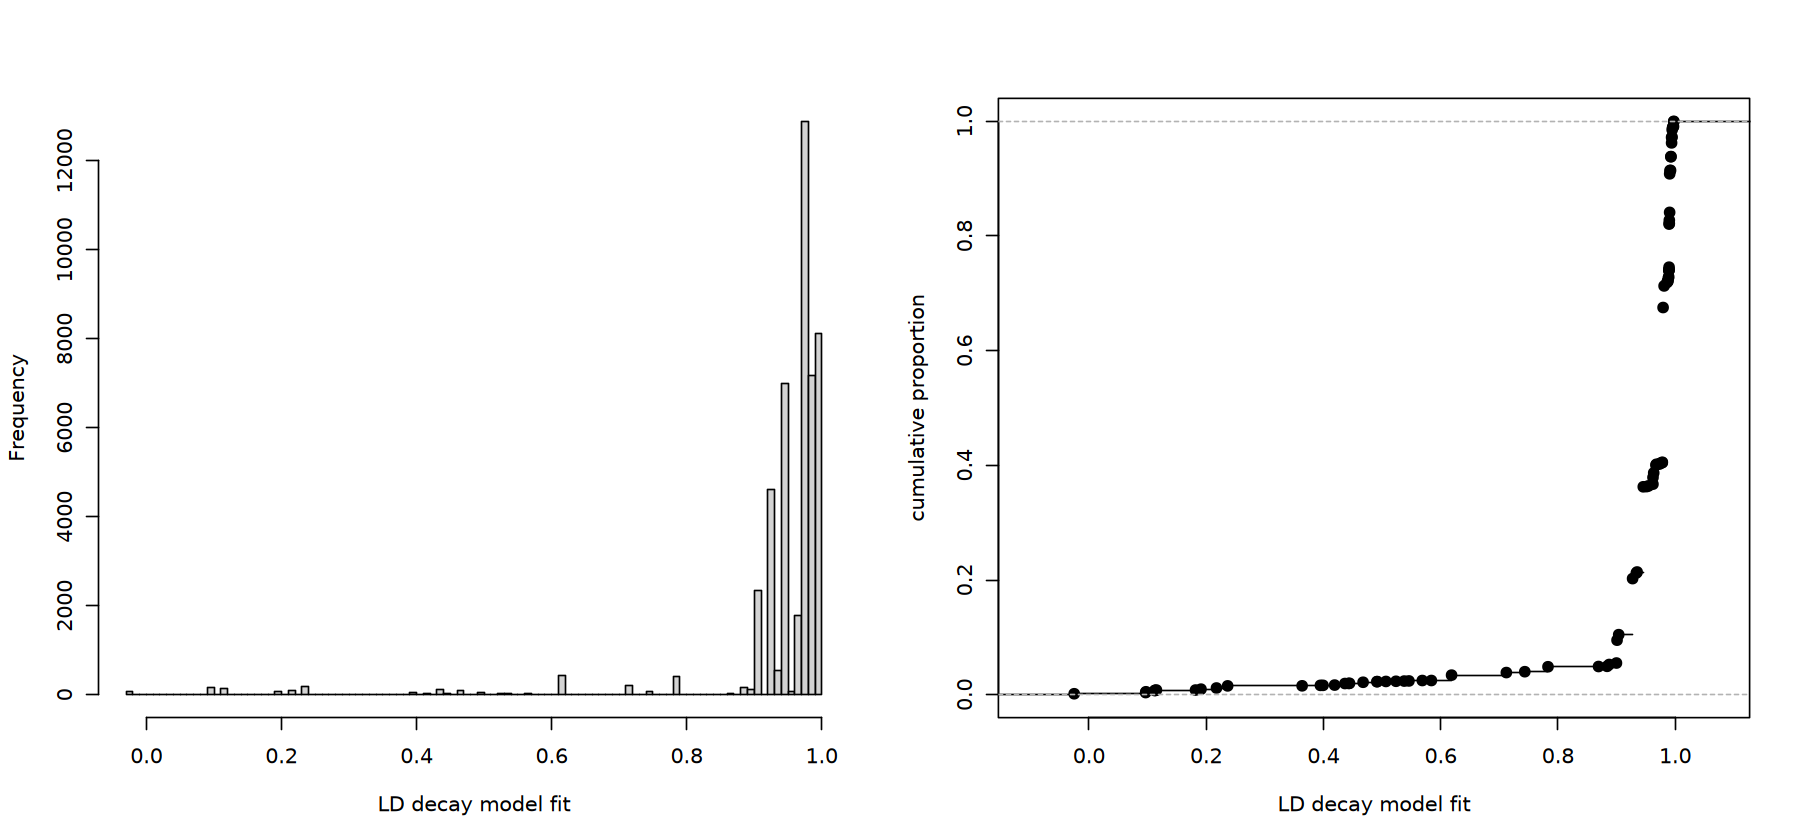

In [38]:
# visualize distribution of model fit for the windows
options(repr.plot.width=15)
op <- par(mfrow=c(1, 2))
hist(gwas_with_genes$LD_decay_fit_R2, breaks=100, main=NULL, xlab='LD decay model fit')
plot(ecdf(gwas_with_genes$LD_decay_fit_R2), main=NULL, xlab='LD decay model fit', ylab='cumulative proportion')
par(op)

In [39]:
# set a cut off for LD-decay model fit based on above plots
ld_decay_cut = 0.9 # User defined based on above plots
poor_ld_idx <- which(gwas_with_genes$LD_decay_fit_R2 < ld_decay_cut)
poor_ld_idx %>% length()

[1] 2601

In [43]:
gwas_hits_in_poor_ld_regions <- gwas_with_genes[poor_ld_idx,1:10] %>% unique()
dim(gwas_hits_in_poor_ld_regions)
head(gwas_hits_in_poor_ld_regions)
write.table(gwas_hits_in_poor_ld_regions, file=paste0(wdir, '/results/gwas_hits_in_poor_ld_regions.txt'), quote=F, row.names=F)

[1] 383  10

,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,trait,model
,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>
26,3_5499477,3,5499477,4.449898e-10,0.055727554,323,4.395912e-04,0.04465348,tgw,BLINK
63,3_27542756,3,27542756,5.228156e-09,0.034055728,323,3.443152e-03,-0.05415738,tgw,BLINK
80,3_5499477,3,5499477,2.643453e-09,0.055727554,323,2.611383e-03,0.03446713,tgw,FarmCPU
1767,6_53761286,6,53761286,1.365310e-12,0.003236246,309,2.697493e-06,-0.06945951,extent,BLINK
1846,6_53761286,6,53761286,8.111329e-09,0.003236246,309,3.205169e-03,-0.04928299,extent,FarmCPU
1906,7_50204215,7,50204215,4.352572e-11,0.037216828,309,7.649765e-05,0.01451887,extent,FarmCPU


In [49]:
# Write correct assignemnts to file
snp2genes <- gwas_with_genes[-(poor_ld_idx),]
head(snp2genes)
write.table(snp2genes, paste0(wdir, '/results/snp2genes.txt'), quote=F, row.names=F)

,SNP,Chr,Pos,P.value,MAF,nobs,H.B.P.Value,Effect,trait,model,⋯,span,up_loc,down_loc,Chr_gene,source,gbkey,gene_start,gene_end,strand,geneID
,<chr>,<int>,<int>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>,<chr>,⋯,<int>,<int>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
1,2_68565136,2,68565136,1.081414e-10,0.003095975,323,0.0002136588,0.268476,tgw,BLINK,⋯,30848,68534288,68595984,2,EMBL,gene,68535646,68536494,+,TAV2_LOCUS8143
2,2_68565136,2,68565136,1.081414e-10,0.003095975,323,0.0002136588,0.268476,tgw,BLINK,⋯,30848,68534288,68595984,2,EMBL,gene,68537182,68539287,-,TAV2_LOCUS8144
3,2_68565136,2,68565136,1.081414e-10,0.003095975,323,0.0002136588,0.268476,tgw,BLINK,⋯,30848,68534288,68595984,2,EMBL,gene,68542602,68546192,+,TAV2_LOCUS8145
4,2_68565136,2,68565136,1.081414e-10,0.003095975,323,0.0002136588,0.268476,tgw,BLINK,⋯,30848,68534288,68595984,2,EMBL,gene,68559125,68561791,+,TAV2_LOCUS8147
5,2_68565136,2,68565136,1.081414e-10,0.003095975,323,0.0002136588,0.268476,tgw,BLINK,⋯,30848,68534288,68595984,2,EMBL,gene,68570320,68573921,+,TAV2_LOCUS8149
6,2_68565136,2,68565136,1.081414e-10,0.003095975,323,0.0002136588,0.268476,tgw,BLINK,⋯,30848,68534288,68595984,2,EMBL,gene,68574136,68577213,-,TAV2_LOCUS8150


[1] 37  2

[1] 37  2

[1] 37  3

,trait,SNPs,genes
,<chr>,<int>,<int>
1,area_convex,2,41
2,aspect_ratio,1,21
3,axis_minor_length,1,19
4,c16_0_methyl_palmitate,12,128
5,c18_1_methyl_oleate,6,218
6,c18_2_methyl_linoleate,3,137


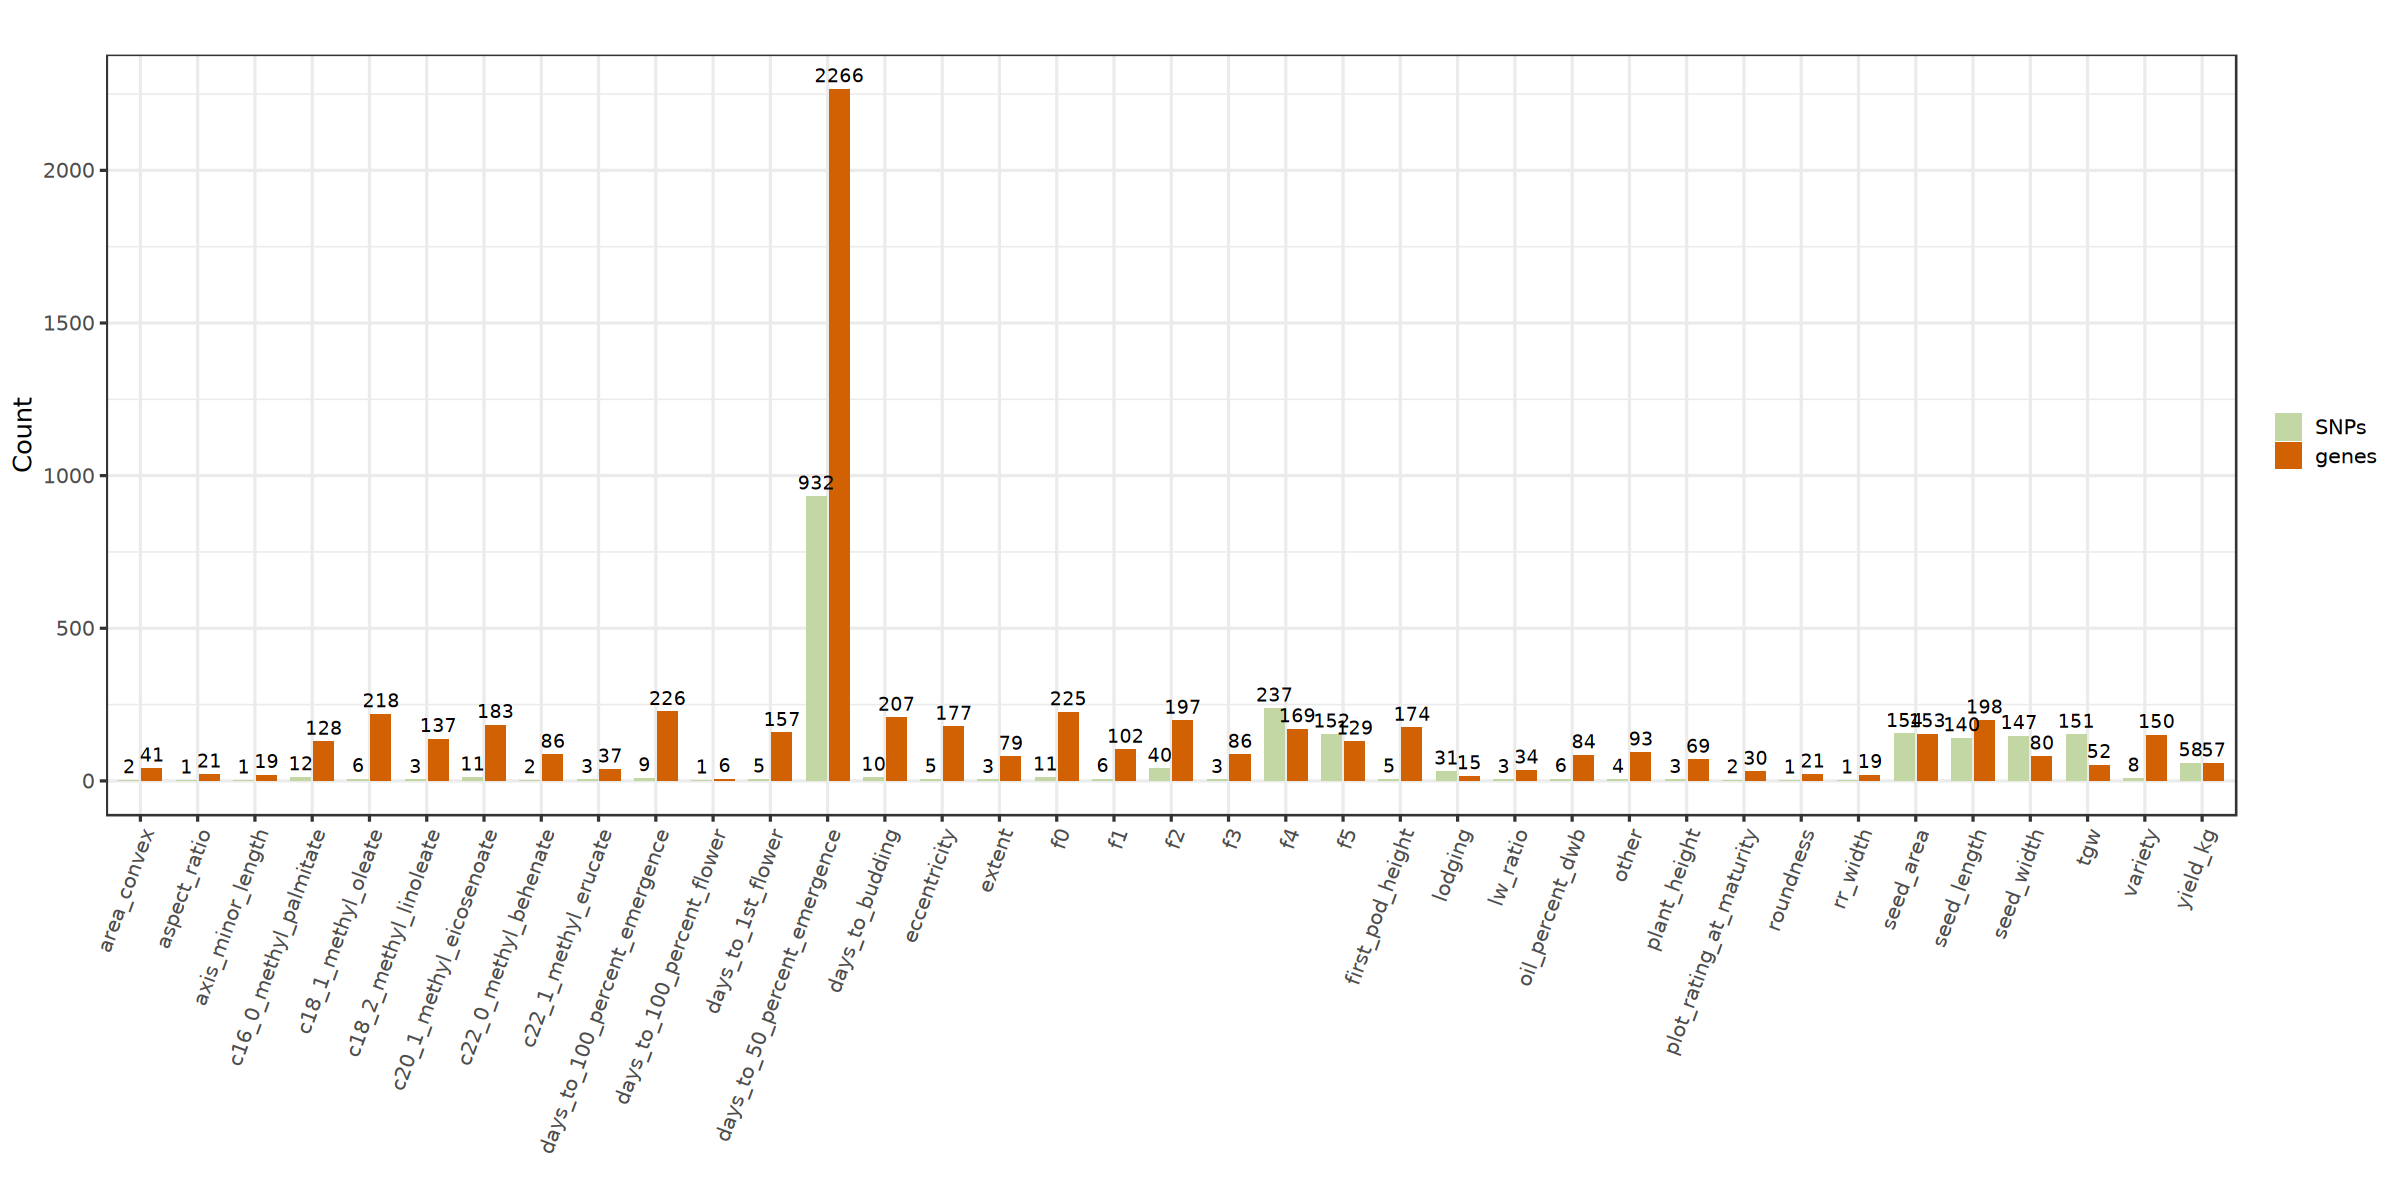

In [59]:
options(repr.plot.width=20, repr.plot.height=10)

SNP_freq <- snp2genes %>% 
select(SNP, trait) %>% 
distinct() %>% 
group_by(trait) %>% 
summarise(SNPs=n())

gene_freq <- snp2genes %>% 
select(geneID, trait) %>% 
distinct() %>% 
group_by(trait) %>% 
summarise(genes=n())

dim(SNP_freq)
dim(gene_freq)

snp2genes_stat = merge(SNP_freq, gene_freq, by='trait')
dim(snp2genes_stat)
head(snp2genes_stat)

snp2genes_stat %>% 
pivot_longer(-1, names_to='type', values_to='freq') %>% 
ggplot(aes(x=trait, y=freq, fill=type)) +
geom_bar(stat="identity", position=position_dodge(width = 0.8), width=0.7) + 
scale_fill_manual(values = c("#C3D7A4", "#D16103")) +
geom_text(aes(label = freq), 
            position = position_dodge(width = 0.8), 
            vjust = -0.5, 
            size = 4) +
theme_bw(base_size=15) +
labs(x="", y="Count", fill=NULL, title="") +
theme(axis.text.x=element_text(angle=70, vjust=1, hjust=1), legend.position="right")

In [ ]:
# END